<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_thermalstate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 35.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 14.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 17.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [qiskit-ibm-runtime]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
drive.mount("/content/drive")


ValueError: mount failed

In [ ]:
qc = QuantumCircuit(2,1)
qc.x(1)
qc.rxx(0.5,0,1)
qc.ryy(0.5,0,1)
psi = qi.Statevector(qc)
rho = qi.DensityMatrix(qi.partial_trace(psi,1))
rho

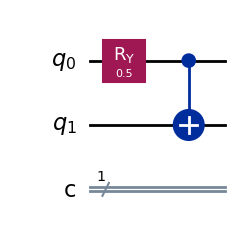

In [21]:
qc = QuantumCircuit(2,1)
qc.ry(0.5,0)
qc.cx(0,1)
qc.draw('mpl')

#psi = qi.Statevector(qc)
#rho = qi.DensityMatrix(qi.partial_trace(psi,1))
#rho

# Load results from Linblad equation

In [ ]:
file_path = (
    '/content/drive/MyDrive/'
    'cont_solution_dt_0.5_g_0.71_omegas_1.txt'
)

data_cont = np.loadtxt(file_path, comments='#')

t_cont = data_cont[:, 0]
sx_cont = data_cont[:, 1]
sy_cont = data_cont[:, 2]
sz_cont = data_cont[:, 3]

# No noise

In [31]:
def sz_2_nonoise_circuit(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5):
  sz_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [32]:
def sx_2_nonoise_circuit(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5):
  sx_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.h(0)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)


    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [33]:
def sy_2_nonoise_circuit(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5):
  sy_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_2_nonoise.append(-valor)
  return sy_2_nonoise

In [34]:
def ps_nonoise_2(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5):
  ps = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.x(2)
    qc.rxx(alpha,1,2)
    qc.ryy(alpha,1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.x(2)
      qc.rxx(alpha,1,2)
      qc.ryy(alpha,1,2)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    ps_value = (results.get('0', 0)) / nshots
    ps.append(ps_value)
  return ps

In [35]:
def ps_nonoise(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5):
  ps = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    ps_value = (results.get('0', 0)) / nshots
    ps.append(ps_value)
  return ps


In [36]:
Gamma = 0.25
delta_t = 0.5
g = np.sqrt(Gamma/delta_t)
omega = 1
N = int(30/delta_t)
nshots = 1024

omega_A = 0.25


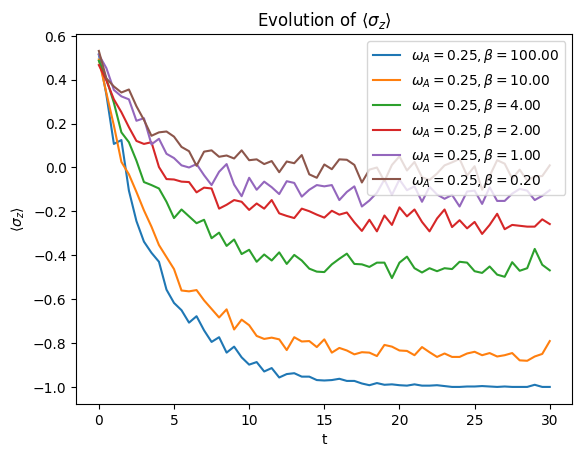

In [88]:
simulator_aer = AerSimulator()
#fig_x, ax_x = plt.subplots()
#fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()
time = np.arange(N+1) * delta_t

for T in [0.01,0.1,0.25,0.5,1,5]:
  beta = 1/T
  alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
  #sx_2_nonoise = sx_2_nonoise_circuit(simulator_aer,alpha, N,g,delta_t)
  #sy_2_nonoise= sy_2_nonoise_circuit(simulator_aer,alpha, N,g,delta_t)
  sz_2_nonoise= sz_2_nonoise_circuit(simulator_aer,alpha, N,g,delta_t)
  #ax_x.plot(time, sx_2_nonoise, label=rf'$\omega_A = {omega_A:.2f}, \beta ={beta:.2f}$')
  #ax_y.plot(time, sy_2_nonoise, label=rf'$\omega_A = {omega_A:.2f}, \beta ={beta:.2f}$')
  ax_z.plot(time, sz_2_nonoise, label=rf'$\omega_A = {omega_A:.2f}, \beta ={beta:.2f}$')

  datos = np.column_stack((time, sz_2_nonoise))

  np.savetxt(
  f"/content/drive/MyDrive/qiskit_thermalstate_sz_ns1024_nonoise_T_{T:.2f}.txt",
  datos,
  header="t sx sy sz",
  fmt="%.10f"
  )



#ax_x.set_xlabel('t')
#ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
#ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ ')
#ax_x.legend()

# Configurar figura de Y
#ax_y.set_xlabel('t')
#ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
#ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$')
#ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$')
ax_z.legend()

plt.show()

#plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
#plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
#plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

#plt.xlabel('t')
#plt.ylabel('Expected Value')
#plt.legend()


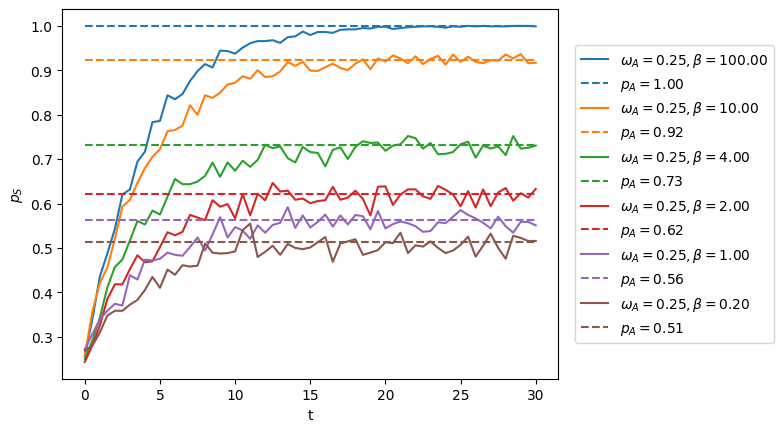

In [68]:
simulator_aer = AerSimulator()
for T in [0.01,0.1,0.25,0.5,1,5]:
  beta = 1/T
  alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
  ps =ps_nonoise(simulator_aer,alpha,N,g,delta_t)

  time = np.arange(N+1) * delta_t
  line, = plt.plot(time, ps, label=rf'$\omega_A = {omega_A}, \beta = {beta:.2f}$')

  plt.hlines(
        y=np.cos(alpha / 2)**2,
        xmin=0,
        xmax=N * delta_t,
        colors=line.get_color(),
        linestyles='dashed',
        label=rf'$p_A = {np.cos(alpha / 2)**2:.2f}$'
    )

  datos = np.column_stack((time, ps))
  np.savetxt(
    f"/content/drive/MyDrive/qiskit_thermalstate_ps_ns1024_nonoise_T_{T:.2f}.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

  #plt.hlines(y=np.cos(alpha)**2,xmin=0,xmax=N*delta_t,linestyles='dashed',label = rf'$p_A = ${np.cos(alpha)**2}')
  plt.xlabel('t')
  plt.ylabel(r'$p_S$')
  plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


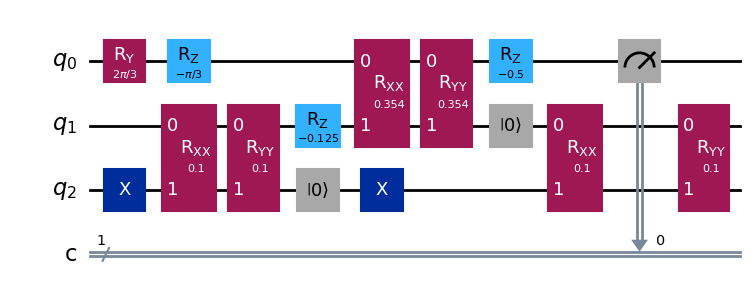

In [39]:
alpha = 0.1
qc = QuantumCircuit(3,1)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.x(2)
qc.rxx(alpha,1,2)
qc.ryy(alpha,1,2)
#psi = qi.Statevector(qc)
#rho = qi.DensityMatrix(psi)
#print(qi.partial_trace(qi.partial_trace(rho, [2]), [0]))
for i in range(0,1):
  qc.rz(-omega_A*delta_t,1)
  qc.rxx(g*delta_t,0,1)
  qc.ryy(g*delta_t,0,1)
  qc.rz(-omega*delta_t,0)
  qc.reset(1)
  qc.reset(2)
  qc.x(2)
  qc.rxx(alpha,1,2)
  qc.ryy(alpha,1,2)
  #rho = qi.DensityMatrix(psi)
  #print(qi.partial_trace(qi.partial_trace(rho, [2]), [0]))
qc.measure(0,0)
qc.draw('mpl')

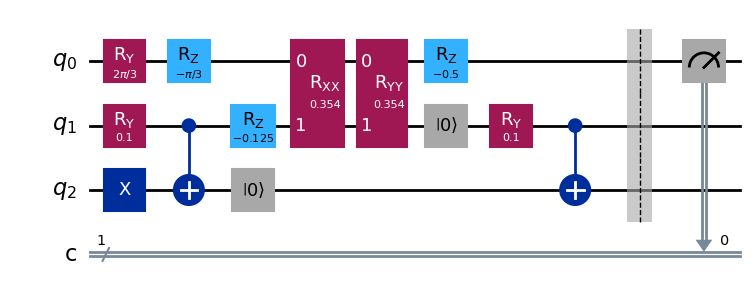

In [41]:
alpha = 0.1
qc = QuantumCircuit(3, 1)

qc.ry(np.pi - np.pi/3, 0)
qc.rz(-np.pi/3, 0)
qc.x(2)
qc.ry(alpha, 1)
qc.cx(1, 2)

for i in range(0, 1):
  qc.rz(-omega_A*delta_t,1)
  qc.rxx(g*delta_t, 0, 1)
  qc.ryy(g*delta_t, 0, 1)
  qc.rz(-omega*delta_t, 0)

  qc.reset(1)
  qc.reset(2)

  qc.ry(alpha, 1)
  qc.cx(1, 2)

# Separar la evolución de la medición
qc.barrier()

# Medición final
qc.measure(0, 0)

qc.draw('mpl')

# Noise

In [48]:
def sz_2_backend_circuit(sim_backend,alpha, N = 30, g = 0.7, delta_t = 0.5, omega = 0.5, omega_A = 0.25):
  sz_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.measure(0,0)

    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [49]:
def sx_2_backend_circuit(sim_backend,alpha, N = 30, g = 0.7, delta_t = 0.5, omega = 0.5, omega_A = 0.25):
  sx_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.h(0)
    qc.measure(0,0)

    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)


    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [50]:
def sy_2_backend_circuit(sim_backend,alpha, N = 30, g = 0.7, delta_t = 0.5, omega = 0.5, omega_A = 0.25):
  sy_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)

    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_2_nonoise.append(-valor)
  return sy_2_nonoise

In [51]:
def ps_backend_2(sim_backend,alpha, N = 30, g = 0.7, delta_t = 0.5, omega = 0.5, omega_A = 0.25):
  ps = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.x(2)
    qc.rxx(alpha,1,2)
    qc.ryy(alpha,1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.x(2)
      qc.rxx(alpha,1,2)
      qc.ryy(alpha,1,2)
    qc.measure(0,0)

    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)

    results = job.result().get_counts()
    ps_value = (results.get('0', 0)) / nshots
    ps.append(ps_value)
  return ps

In [63]:
def ps_backend(sim_backend,alpha, N = 30, g = 0.7, delta_t = 0.5, omega = 0.5, omega_A = 0.25):
  ps = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.measure(0,0)

    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)

    results = job.result().get_counts()
    ps_value = (results.get('0', 0)) / nshots
    ps.append(ps_value)
  return ps


In [60]:
Gamma = 0.25
delta_t = 0.5
g = np.sqrt(Gamma/delta_t)
omega = 1
N = int(30/delta_t)
nshots = 1024

omega_A = 0.25


qiskit_runtime_service._discover_account:WARNING:2026-10-24 00:19:50,669: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-24 00:19:54,217: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-24 00:19:54,218: Using instance: open-instance, plan: open


0.01
0.1
0.25
0.5
1.0
5.0


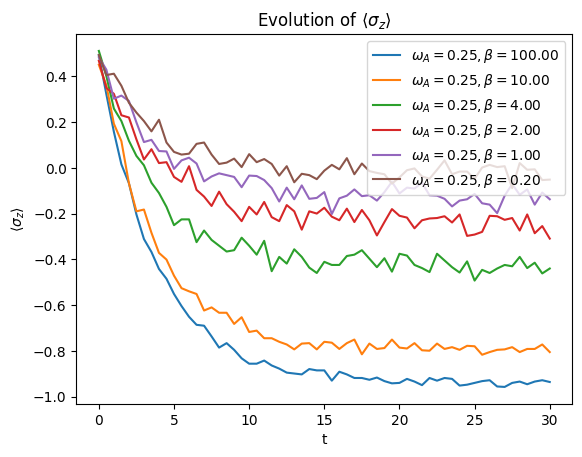

In [87]:
service = QiskitRuntimeService(channel="ibm_quantum_platform", token="")
real_backend = service.backend("ibm_fez")
sim_backend = AerSimulator.from_backend(real_backend)

#fig_x, ax_x = plt.subplots()
#fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()
time = np.arange(N+1) * delta_t

for T in [0.01, 0.10, 0.25, 0.50, 1.0, 5.0]:
  print(T)
  beta = 1/T
  alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
  #sx_2_backend = sx_2_backend_circuit(sim_backend,alpha, N,g,delta_t, omega, omega_A)
  #sy_2_backend= sy_2_backend_circuit(sim_backend,alpha, N,g,delta_t)
  sz_2_backend= sz_2_backend_circuit(sim_backend,alpha, N,g,delta_t)
  #ax_x.plot(time, sx_2_backend, label=rf'$\omega_A = {omega_A:.2f}, \beta ={beta:.2f}$')
  #ax_y.plot(time, sy_2_backend, label=rf'$\omega_A = {omega_A:.2f}, \beta ={beta:.2f}$')
  ax_z.plot(time, sz_2_backend, label=rf'$\omega_A = {omega_A:.2f}, \beta ={beta:.2f}$')

  datos = np.column_stack((time, sz_2_backend))

  np.savetxt(
  f"/content/drive/MyDrive/qiskit_thermalstate_sz_ns1024_fez_T_{T:.2f}.txt",
  datos,
  header="t sx sy sz",
  fmt="%.10f"
  )

#ax_x.set_xlabel('t')
#ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
#ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ ')
#ax_x.legend()

# Configurar figura de Y
#ax_y.set_xlabel('t')
#ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
#ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$')
#ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$')
ax_z.legend()

plt.show()

#plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
#plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
#plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

#plt.xlabel('t')
#plt.ylabel('Expected Value')
#plt.legend()


qiskit_runtime_service._discover_account:WARNING:2026-10-24 00:04:08,800: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-24 00:04:13,200: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-24 00:04:13,201: Using instance: open-instance, plan: open


0.25


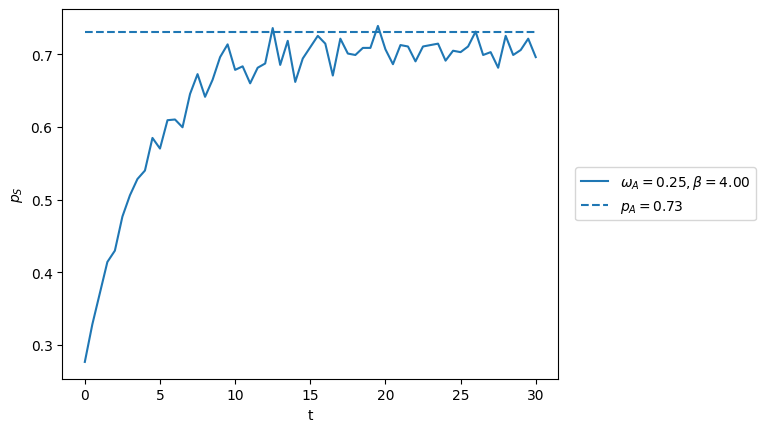

In [82]:
service = QiskitRuntimeService(channel="ibm_quantum_platform", token="")
real_backend = service.backend("ibm_marrakesh")
sim_backend = AerSimulator.from_backend(real_backend)

simulator_aer = AerSimulator()
for T in [0.01, 0.10, 0.25, 0.50, 1.0, 5.0]:
  print(T)
  beta = 1/T
  alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
  ps =ps_backend(sim_backend,alpha,N,g,delta_t, omega, omega_A)

  time = np.arange(N+1) * delta_t
  line, = plt.plot(time, ps, label=rf'$\omega_A = {omega_A}, \beta = {beta:.2f}$')

  plt.hlines(
        y=np.cos(alpha / 2)**2,
        xmin=0,
        xmax=N * delta_t,
        colors=line.get_color(),
        linestyles='dashed',
        label=rf'$p_A = {np.cos(alpha / 2)**2:.2f}$'
    )

  datos = np.column_stack((time, ps))
  np.savetxt(
    f"/content/drive/MyDrive/qiskit_thermalstate_ps_ns1024_marrakesh_T_{T:.2f}.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

  #plt.hlines(y=np.cos(alpha)**2,xmin=0,xmax=N*delta_t,linestyles='dashed',label = rf'$p_A = ${np.cos(alpha)**2}')
  plt.xlabel('t')
  plt.ylabel(r'$p_S$')
  plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


## Plot fez and no noise

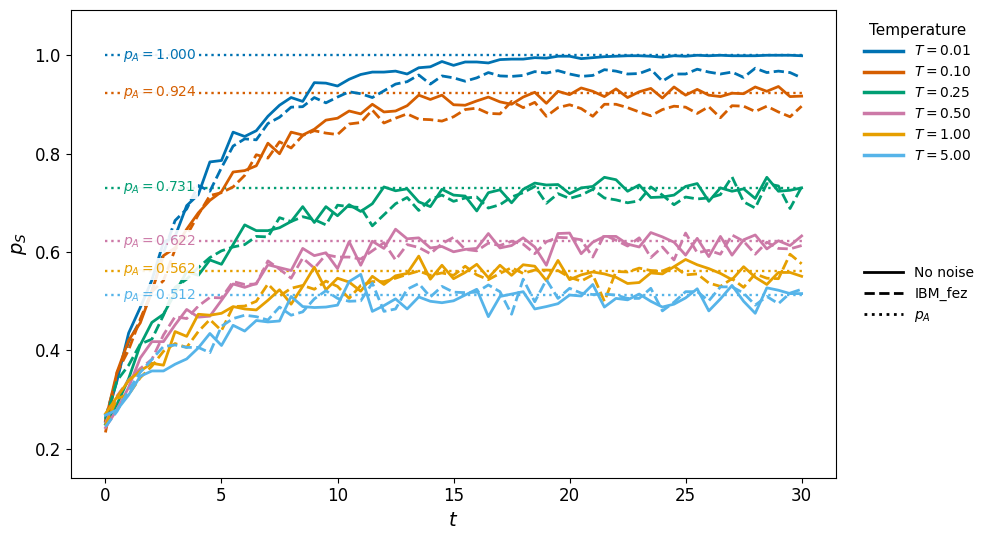

In [75]:


# Temperaturas
Ts = [0.01, 0.10, 0.25, 0.50, 1.0, 5.0]

# omega_A debe estar definido previamente
# omega_A = ...

# Colores personalizados
colors = ['#0072B2', '#D55E00', '#009E73',
          '#CC79A7', '#E69F00', '#56B4E9']

fig, ax = plt.subplots(figsize=(10, 5.5))

path = "/content/drive/MyDrive/"

# Guardar información de las horizontales
etiquetas_pa = []

for T, color in zip(Ts, colors):

    # Parámetros térmicos
    beta = 1 / T
    p_A = 1 / (1 + np.exp(-beta * omega_A))

    # Archivos
    file_nonoise = (
        f"{path}qiskit_thermalstate_ps_ns1024_nonoise_T_{T:.2f}.txt"
    )
    file_fez = (
        f"{path}qiskit_thermalstate_ps_ns1024_fez_T_{T:.2f}.txt"
    )

    # Leer datos
    data_nonoise = np.loadtxt(file_nonoise)
    data_fez = np.loadtxt(file_fez)

    t_nonoise = data_nonoise[:, 0]
    ps_nonoise = data_nonoise[:, 1]

    t_fez = data_fez[:, 0]
    ps_fez = data_fez[:, 1]

    # No noise: línea continua
    ax.plot(
        t_nonoise, ps_nonoise,
        color=color,
        linestyle='-',
        linewidth=2,
        zorder=2
    )

    # FEZ: línea discontinua
    ax.plot(
        t_fez, ps_fez,
        color=color,
        linestyle='--',
        linewidth=2,
        zorder=2
    )

    # Horizontal teórica
    xmin = min(t_nonoise.min(), t_fez.min())
    xmax = max(t_nonoise.max(), t_fez.max())

    ax.hlines(
        y=p_A,
        xmin=xmin,
        xmax=xmax,
        colors=color,
        linestyles=':',
        linewidth=1.7,
        zorder=1
    )

    # Guardar información para las etiquetas
    etiquetas_pa.append((p_A, color, xmin, xmax))


# --------------------------------------------------
# ESTÉTICA DE LOS EJES
# --------------------------------------------------

ax.set_xlabel(r'$t$', fontsize=14)
ax.set_ylabel(r'$p_S$', fontsize=14)

ax.tick_params(axis='both', labelsize=12)

# Márgenes verticales para las etiquetas
ax.margins(y=0.12)


# --------------------------------------------------
# ETIQUETAS p_A SIN SOLAPAMIENTOS
# --------------------------------------------------

# Ordenar por valor de p_A
etiquetas_pa.sort(key=lambda x: x[0])

# Actualizar transformaciones
fig.canvas.draw()

# Separación mínima entre etiquetas (puntos)
separacion = 17
min_sep_px = separacion * fig.dpi / 72

# Posiciones originales en píxeles
posiciones = [
    ax.transData.transform((0, p_A))[1]
    for p_A, color, xmin, xmax in etiquetas_pa
]

# Límites verticales del área de dibujo
ymin_px = ax.bbox.ymin + 12
ymax_px = ax.bbox.ymax - 12

# Separar etiquetas cercanas
for i in range(1, len(posiciones)):
    posiciones[i] = max(
        posiciones[i],
        posiciones[i - 1] + min_sep_px
    )

# Desplazar todas hacia abajo si exceden el límite superior
if posiciones[-1] > ymax_px:
    desplazamiento = posiciones[-1] - ymax_px
    posiciones = [y - desplazamiento for y in posiciones]

# Desplazar hacia arriba si exceden el límite inferior
if posiciones[0] < ymin_px:
    desplazamiento = ymin_px - posiciones[0]
    posiciones = [y + desplazamiento for y in posiciones]

# Dibujar las etiquetas
for (p_A, color, xmin, xmax), y_pixel in zip(
    etiquetas_pa, posiciones
):

    x = xmin + 0.025 * (xmax - xmin)

    # Convertir coordenadas de pantalla a datos
    y_text = ax.transData.inverted().transform(
        (0, y_pixel)
    )[1]

    ax.annotate(
        rf'$p_A={p_A:.3f}$',
        xy=(x, p_A),
        xytext=(x, y_text),
        textcoords='data',
        color=color,
        fontsize=10,
        fontweight='medium',
        ha='left',
        va='center',
        zorder=20,
        annotation_clip=False,
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.9,
            pad=2
        ),
        arrowprops=dict(
            arrowstyle='-',
            color=color,
            linewidth=0.8,
            alpha=0.7
        )
    )


# --------------------------------------------------
# LEYENDA 1: TEMPERATURAS
# --------------------------------------------------

temp_handles = [
    Line2D(
        [0], [0],
        color=color,
        lw=2.5,
        linestyle='-',
        label=rf'$T={T:.2f}$'
    )
    for T, color in zip(Ts, colors)
]

legend1 = ax.legend(
    handles=temp_handles,
    title='Temperature',
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    fontsize=10,
    title_fontsize=11,
    frameon=False,
    handlelength=2.8
)

ax.add_artist(legend1)


# --------------------------------------------------
# LEYENDA 2: TIPOS DE LÍNEA
# --------------------------------------------------

style_handles = [
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle='-',
        label='No noise'
    ),
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle='--',
        label='IBM_fez'
    ),
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle=':',
        label=r'$p_A$'
    )
]

ax.legend(
    handles=style_handles,
    title='',
    loc='upper left',
    bbox_to_anchor=(1.02, 0.48),
    fontsize=10,
    title_fontsize=11,
    frameon=False,
    handlelength=2.8
)


# --------------------------------------------------
# MOSTRAR Y GUARDAR
# --------------------------------------------------

plt.tight_layout()

plt.savefig(
    path + "qiskit_thermalstate_comparison.pdf",
    bbox_inches='tight'
)

plt.savefig(
    path + "qiskit_thermalstate_comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## Plot marrakesh and no noise

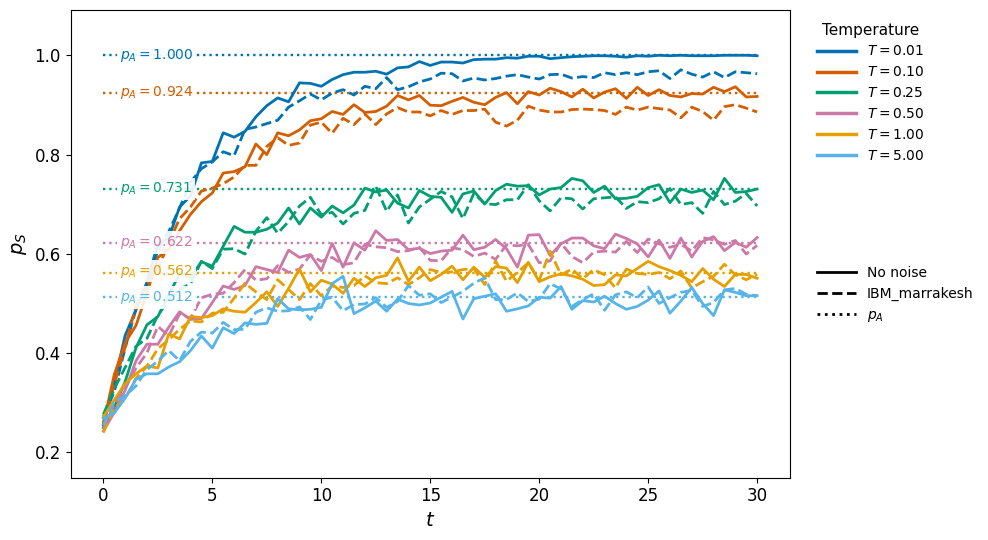

In [83]:


# Temperaturas
Ts = [0.01, 0.10, 0.25, 0.50, 1.0, 5.0]

# omega_A debe estar definido previamente
# omega_A = ...

# Colores personalizados
colors = ['#0072B2', '#D55E00', '#009E73',
          '#CC79A7', '#E69F00', '#56B4E9']

fig, ax = plt.subplots(figsize=(10, 5.5))

path = "/content/drive/MyDrive/"

# Guardar información de las horizontales
etiquetas_pa = []

for T, color in zip(Ts, colors):

    # Parámetros térmicos
    beta = 1 / T
    p_A = 1 / (1 + np.exp(-beta * omega_A))

    # Archivos
    file_nonoise = (
        f"{path}qiskit_thermalstate_ps_ns1024_nonoise_T_{T:.2f}.txt"
    )
    file_fez = (
        f"{path}qiskit_thermalstate_ps_ns1024_marrakesh_T_{T:.2f}.txt"
    )

    # Leer datos
    data_nonoise = np.loadtxt(file_nonoise)
    data_fez = np.loadtxt(file_fez)

    t_nonoise = data_nonoise[:, 0]
    ps_nonoise = data_nonoise[:, 1]

    t_fez = data_fez[:, 0]
    ps_fez = data_fez[:, 1]

    # No noise: línea continua
    ax.plot(
        t_nonoise, ps_nonoise,
        color=color,
        linestyle='-',
        linewidth=2,
        zorder=2
    )

    # FEZ: línea discontinua
    ax.plot(
        t_fez, ps_fez,
        color=color,
        linestyle='--',
        linewidth=2,
        zorder=2
    )

    # Horizontal teórica
    xmin = min(t_nonoise.min(), t_fez.min())
    xmax = max(t_nonoise.max(), t_fez.max())

    ax.hlines(
        y=p_A,
        xmin=xmin,
        xmax=xmax,
        colors=color,
        linestyles=':',
        linewidth=1.7,
        zorder=1
    )

    # Guardar información para las etiquetas
    etiquetas_pa.append((p_A, color, xmin, xmax))


# --------------------------------------------------
# ESTÉTICA DE LOS EJES
# --------------------------------------------------

ax.set_xlabel(r'$t$', fontsize=14)
ax.set_ylabel(r'$p_S$', fontsize=14)

ax.tick_params(axis='both', labelsize=12)

# Márgenes verticales para las etiquetas
ax.margins(y=0.12)


# --------------------------------------------------
# ETIQUETAS p_A SIN SOLAPAMIENTOS
# --------------------------------------------------

# Ordenar por valor de p_A
etiquetas_pa.sort(key=lambda x: x[0])

# Actualizar transformaciones
fig.canvas.draw()

# Separación mínima entre etiquetas (puntos)
separacion = 17
min_sep_px = separacion * fig.dpi / 72

# Posiciones originales en píxeles
posiciones = [
    ax.transData.transform((0, p_A))[1]
    for p_A, color, xmin, xmax in etiquetas_pa
]

# Límites verticales del área de dibujo
ymin_px = ax.bbox.ymin + 12
ymax_px = ax.bbox.ymax - 12

# Separar etiquetas cercanas
for i in range(1, len(posiciones)):
    posiciones[i] = max(
        posiciones[i],
        posiciones[i - 1] + min_sep_px
    )

# Desplazar todas hacia abajo si exceden el límite superior
if posiciones[-1] > ymax_px:
    desplazamiento = posiciones[-1] - ymax_px
    posiciones = [y - desplazamiento for y in posiciones]

# Desplazar hacia arriba si exceden el límite inferior
if posiciones[0] < ymin_px:
    desplazamiento = ymin_px - posiciones[0]
    posiciones = [y + desplazamiento for y in posiciones]

# Dibujar las etiquetas
for (p_A, color, xmin, xmax), y_pixel in zip(
    etiquetas_pa, posiciones
):

    x = xmin + 0.025 * (xmax - xmin)

    # Convertir coordenadas de pantalla a datos
    y_text = ax.transData.inverted().transform(
        (0, y_pixel)
    )[1]

    ax.annotate(
        rf'$p_A={p_A:.3f}$',
        xy=(x, p_A),
        xytext=(x, y_text),
        textcoords='data',
        color=color,
        fontsize=10,
        fontweight='medium',
        ha='left',
        va='center',
        zorder=20,
        annotation_clip=False,
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.9,
            pad=2
        ),
        arrowprops=dict(
            arrowstyle='-',
            color=color,
            linewidth=0.8,
            alpha=0.7
        )
    )


# --------------------------------------------------
# LEYENDA 1: TEMPERATURAS
# --------------------------------------------------

temp_handles = [
    Line2D(
        [0], [0],
        color=color,
        lw=2.5,
        linestyle='-',
        label=rf'$T={T:.2f}$'
    )
    for T, color in zip(Ts, colors)
]

legend1 = ax.legend(
    handles=temp_handles,
    title='Temperature',
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    fontsize=10,
    title_fontsize=11,
    frameon=False,
    handlelength=2.8
)

ax.add_artist(legend1)


# --------------------------------------------------
# LEYENDA 2: TIPOS DE LÍNEA
# --------------------------------------------------

style_handles = [
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle='-',
        label='No noise'
    ),
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle='--',
        label='IBM_marrakesh'
    ),
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle=':',
        label=r'$p_A$'
    )
]

ax.legend(
    handles=style_handles,
    title='',
    loc='upper left',
    bbox_to_anchor=(1.02, 0.48),
    fontsize=10,
    title_fontsize=11,
    frameon=False,
    handlelength=2.8
)


# --------------------------------------------------
# MOSTRAR Y GUARDAR
# --------------------------------------------------

plt.tight_layout()

plt.savefig(
    path + "qiskit_thermalstate_comparison.pdf",
    bbox_inches='tight'
)

plt.savefig(
    path + "qiskit_thermalstate_comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## Plot IBM noise vs no noise sz

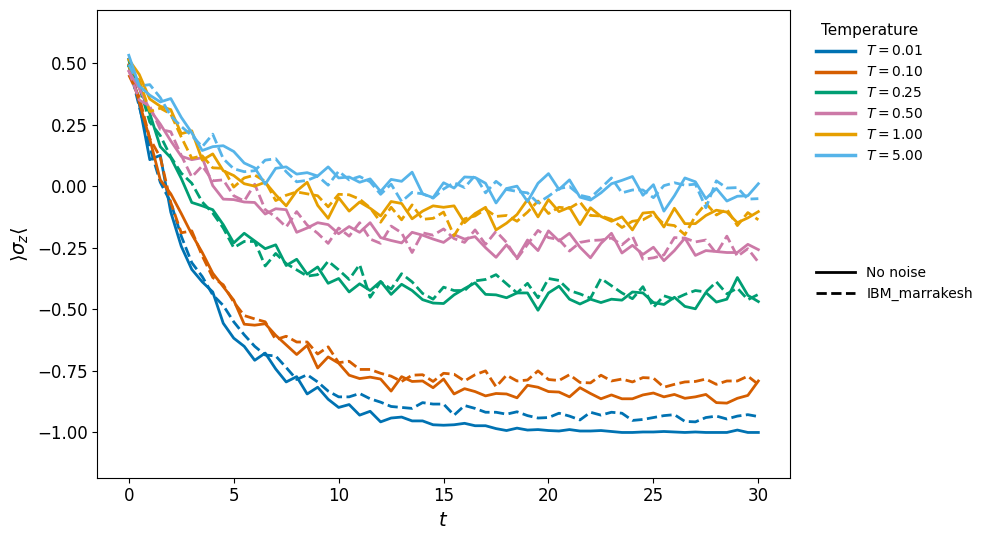

In [89]:


# Temperaturas
Ts = [0.01, 0.10, 0.25, 0.50, 1.0, 5.0]

# omega_A debe estar definido previamente
# omega_A = ...

# Colores personalizados
colors = ['#0072B2', '#D55E00', '#009E73',
          '#CC79A7', '#E69F00', '#56B4E9']

fig, ax = plt.subplots(figsize=(10, 5.5))

path = "/content/drive/MyDrive/"

# Guardar información de las horizontales
etiquetas_pa = []

for T, color in zip(Ts, colors):

    # Parámetros térmicos
    beta = 1 / T
    p_A = 1 / (1 + np.exp(-beta * omega_A))

    # Archivos
    file_nonoise = (
        f"{path}qiskit_thermalstate_sz_ns1024_nonoise_T_{T:.2f}.txt"
    )
    file_fez = (
        f"{path}qiskit_thermalstate_sz_ns1024_fez_T_{T:.2f}.txt"
    )

    # Leer datos
    data_nonoise = np.loadtxt(file_nonoise)
    data_fez = np.loadtxt(file_fez)

    t_nonoise = data_nonoise[:, 0]
    ps_nonoise = data_nonoise[:, 1]

    t_fez = data_fez[:, 0]
    ps_fez = data_fez[:, 1]

    # No noise: línea continua
    ax.plot(
        t_nonoise, ps_nonoise,
        color=color,
        linestyle='-',
        linewidth=2,
        zorder=2
    )

    # FEZ: línea discontinua
    ax.plot(
        t_fez, ps_fez,
        color=color,
        linestyle='--',
        linewidth=2,
        zorder=2
    )




# --------------------------------------------------
# ESTÉTICA DE LOS EJES
# --------------------------------------------------

ax.set_xlabel(r'$t$', fontsize=14)
ax.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize=14)

ax.tick_params(axis='both', labelsize=12)

# Márgenes verticales para las etiquetas
ax.margins(y=0.12)


# --------------------------------------------------
# LEYENDA 1: TEMPERATURAS
# --------------------------------------------------

temp_handles = [
    Line2D(
        [0], [0],
        color=color,
        lw=2.5,
        linestyle='-',
        label=rf'$T={T:.2f}$'
    )
    for T, color in zip(Ts, colors)
]

legend1 = ax.legend(
    handles=temp_handles,
    title='Temperature',
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    fontsize=10,
    title_fontsize=11,
    frameon=False,
    handlelength=2.8
)

ax.add_artist(legend1)


# --------------------------------------------------
# LEYENDA 2: TIPOS DE LÍNEA
# --------------------------------------------------

style_handles = [
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle='-',
        label='No noise'
    ),
    Line2D(
        [0], [0],
        color='black',
        lw=2,
        linestyle='--',
        label='IBM_marrakesh'
    )
]

ax.legend(
    handles=style_handles,
    title='',
    loc='upper left',
    bbox_to_anchor=(1.02, 0.48),
    fontsize=10,
    title_fontsize=11,
    frameon=False,
    handlelength=2.8
)


# --------------------------------------------------
# MOSTRAR Y GUARDAR
# --------------------------------------------------

plt.tight_layout()

plt.show()
